# Profile: PID2Graph

What is in the P&ID graphs (symbols = nodes with a box and a label, lines = edges), what is
missing, how the values are spread, and what one real drawing's graph looks like. The main
question for Module C: how different are the **12 real** drawings from the synthetic ones?

| | |
|---|---|
| **What** | P&ID drawings as images + graphs (symbols = nodes with box and label, lines = edges) |
| **Source** | https://zenodo.org/records/14803338, DOI `10.5281/zenodo.14803338`, published 2025-02-14 |
| **License** | The Zenodo record says **CC BY-SA 4.0** (credit the authors; anything made from the data is shared under the same license). The OPEN100 part is "taken from open-100.com" with **no license given** |
| **Citation** | Stürmer, J. M., Graumann, M., & Koch, T. (2025). *From Engineering Diagrams to Graphs: Digitizing P&IDs with Transformers*. 2025 IEEE 12th International Conference on Data Science and Advanced Analytics (DSAA). https://doi.org/10.1109/DSAA65442.2025.11248012 |

Copied from [`data/DATA_CATALOG.md`](../data/DATA_CATALOG.md). Spec:
[`specs/2026-10-16-profiling-notebooks/`](../specs/2026-10-16-profiling-notebooks/spec.md).

Run headless (inside the container, about two minutes):
`uv run --with jupyterlab jupyter nbconvert --to notebook --execute --inplace notebooks/00_profile_pid2graph.ipynb`

Three subsets in `Complete/`: **PID2Graph OPEN100** (12 real drawings), **PID2Graph Synthetic**
(250) and **Dataset PID** (500, a converted copy of Dataset-P&ID). Image sizes come from the file
header; no drawing is decoded or shown (owner decision: text samples only).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.common import config
from src.datasets.profiling import graphml_boxes, graphml_stats, image_sizes, read_graphml

plt.rcParams.update({"figure.dpi": 72, "figure.figsize": (10, 3)})
pd.set_option("display.max_columns", 30, "display.width", 120)

COMPLETE = config.RAW_DIR / "pid" / "pid2graph" / "PID2Graph" / "Complete"
SUBSETS = {"real (OPEN100)": "PID2Graph OPEN100", "synthetic": "PID2Graph Synthetic",
           "Dataset PID": "Dataset PID"}  # fmt: skip
stats, boxes, images = [], [], []
for name, folder in SUBSETS.items():  # parses 762 .graphml files: about a minute
    stats.append(graphml_stats(COMPLETE / folder).assign(subset=name))
    boxes.append(graphml_boxes(COMPLETE / folder).assign(subset=name))
    images.append(image_sizes(COMPLETE / folder).assign(subset=name))
stats, boxes, images = (pd.concat(t, ignore_index=True) for t in (stats, boxes, images))
order = list(SUBSETS)

## 1. Counts

In [2]:
counts = stats.groupby("subset").agg(
    drawings=("file", "size"), nodes=("nodes", "sum"), edges=("edges", "sum")
)
counts["images"] = images.groupby("subset").size()
counts["node_labels"] = boxes.groupby("subset")["label"].nunique()
counts = counts.reindex(order)
print(f"total drawings: {counts['drawings'].sum()}, images: {counts['images'].sum()}")
counts

total drawings: 762, images: 762


,drawings,nodes,edges,images,node_labels
subset,,,,,
real (OPEN100),12,4629,4567,12,10
synthetic,250,32812,33265,250,7
Dataset PID,500,227757,252526,500,7


## 2. Missing values

Drawings without nodes or edges, nodes without a box or label, and graphs without an image (or
the other way round).

In [3]:
stats["stem"] = stats["file"].str.rsplit(".", n=1).str[0]
images["stem"] = images["file"].str.rsplit(".", n=1).str[0]
gaps = (
    stats.groupby("subset")
    .agg(
        no_nodes=("nodes", lambda n: int((n == 0).sum())),
        no_edges=("edges", lambda n: int((n == 0).sum())),
        nodes_no_box=("no_box", "sum"),
        nodes_no_label=("no_label", "sum"),
    )
    .reindex(order)
)
graph_keys = set(zip(stats["subset"], stats["stem"], strict=True))
image_keys = set(zip(images["subset"], images["stem"], strict=True))
gaps["graph_without_image"] = [sum(k[0] == s for k in graph_keys - image_keys) for s in order]
gaps["image_without_graph"] = [sum(k[0] == s for k in image_keys - graph_keys) for s in order]
gaps

,no_nodes,no_edges,nodes_no_box,nodes_no_label,graph_without_image,image_without_graph
subset,,,,,,
real (OPEN100),0,0,0,0,0,0
synthetic,0,0,0,0,0,0
Dataset PID,0,0,0,0,0,0


## 3. Distributions

Image sizes, graph size per drawing, symbol labels, and **symbol box sizes in pixels**: the box
size decides how drawings must be tiled for a detector.

In [4]:
images.groupby("subset")[["width", "height"]].describe().reindex(order).round(0)

width                                                        height                                 \
                count    mean    std     min     25%     50%     75%     max  count    mean    std     min     25%   
subset                                                                                                               
real (OPEN100)   12.0  2764.0  464.0  1994.0  2292.0  2789.0  3194.0  3342.0   12.0  1844.0  307.0  1330.0  1536.0   
synthetic       250.0  7000.0    0.0  7000.0  7000.0  7000.0  7000.0  7000.0  250.0  4500.0    0.0  4500.0  4500.0   
Dataset PID     500.0  7168.0    0.0  7168.0  7168.0  7168.0  7168.0  7168.0  500.0  4561.0    0.0  4561.0  4561.0   

                                        
                   50%     75%     max  
subset                                  
real (OPEN100)  1861.0  2128.0  2222.0  
synthetic       4500.0  4500.0  4500.0  
Dataset PID     4561.0  4562.0  4562.0

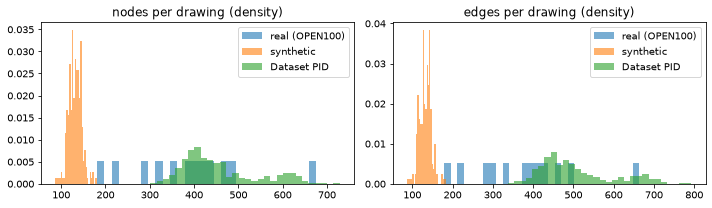

,nodes,edges
subset,,
real (OPEN100),395.0,391.0
synthetic,132.0,133.0
Dataset PID,431.0,479.5


In [5]:
fig, axes = plt.subplots(1, 2)
for ax, col in zip(axes, ["nodes", "edges"], strict=True):
    for name in order:
        ax.hist(
            stats.loc[stats["subset"] == name, col], bins=30, alpha=0.6, density=True, label=name
        )
    ax.set_title(f"{col} per drawing (density)")
    ax.legend()
plt.tight_layout()
plt.show()
stats.groupby("subset")[["nodes", "edges"]].median().reindex(order)

In [6]:
labels = boxes.pivot_table(index="label", columns="subset", values="file", aggfunc="size")
labels = labels.reindex(columns=order).fillna(0).astype(int)
(labels / labels.sum() * 100).round(1).assign(**{"real (OPEN100) count": labels[order[0]]})

subset,real (OPEN100),synthetic,Dataset PID,real (OPEN100) count
label,,,,
arrow,9.7,0.2,0.7,451
background,1.0,0.0,0.9,48
connector,52.0,30.0,50.5,2408
crossing,15.9,52.9,22.5,734
general,5.1,11.6,7.7,234
inlet/outlet,2.1,0.0,0.0,96
instrumentation,7.6,0.0,5.3,350
pump,0.3,1.3,0.0,16
tank,0.8,2.1,0.0,35


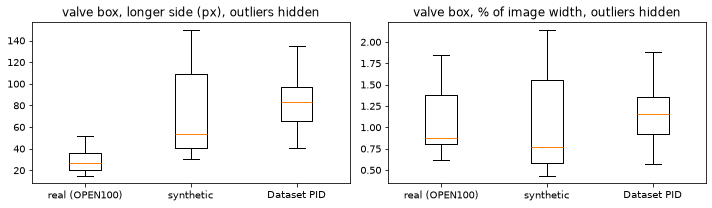

median longer side (px) per label; NaN = label not used in that subset


subset,real (OPEN100),synthetic,Dataset PID
label,,,
arrow,14.0,95.0,62.0
background,2157.0,NaN,5865.0
connector,8.0,8.0,8.0
crossing,8.0,8.0,8.0
general,15.0,165.0,82.0
inlet/outlet,200.0,NaN,NaN
instrumentation,43.0,NaN,116.0
pump,68.0,102.0,NaN
tank,330.0,212.0,NaN


In [7]:
# Box size = longer side in px; also relative to the image width (real images are smaller)
boxes = boxes.merge(images[["subset", "file", "width"]].rename(columns={"width": "image_width"})
                    .assign(file=lambda d: d["file"].str.rsplit(".", n=1).str[0] + ".graphml"),
                    on=["subset", "file"], how="left")  # fmt: skip
boxes["side"] = boxes[["width", "height"]].max(axis=1)
boxes["side_pct"] = boxes["side"] / boxes["image_width"] * 100
valves = boxes[boxes["label"] == "valve"]
fig, axes = plt.subplots(1, 2)
for ax, col, title in [(axes[0], "side", "valve box, longer side (px)"),
                       (axes[1], "side_pct", "valve box, % of image width")]:  # fmt: skip
    ax.boxplot([valves.loc[valves["subset"] == s, col] for s in order], showfliers=False)
    ax.set_xticks(range(1, len(order) + 1), order)
    ax.set_title(f"{title}, outliers hidden")
plt.tight_layout()
plt.show()
side = boxes.groupby(["label", "subset"])["side"].median().unstack().reindex(columns=order)
print("median longer side (px) per label; NaN = label not used in that subset")
side.round(0)

## 4. Sample records

Nodes and edges of the first real drawing (OPEN100), first rows only; no image (owner decision).
Source: PID2Graph, Stürmer et al. 2025, CC BY-SA 4.0 record; OPEN100 part from open-100.com
(no license given), see the header.

In [8]:
real_dir = COMPLETE / SUBSETS["real (OPEN100)"]
sample_file = sorted(real_dir.glob("*.graphml"))[0]
nodes, edges = read_graphml(sample_file)
print(f"{sample_file.name}: {len(nodes)} nodes, {len(edges)} edges")
nodes.head(8)

0.graphml: 437 nodes, 433 edges


,id,label,xmin,ymin,xmax,ymax
0,general1,general,1151.21,690.15,1170.20,702.50
1,general2,general,324.49,1076.19,332.44,1089.32
2,general3,general,288.52,1327.10,302.72,1338.30
3,general4,general,232.82,1327.10,247.52,1338.30
4,general5,general,677.45,785.24,685.85,798.92
5,general6,general,643.54,1003.94,656.84,1012.14
6,general7,general,607.34,1004.34,621.34,1012.44
7,general8,general,578.32,930.28,586.84,944.80


In [9]:
edges.head(8)

,source,target,label
0,general1,connector159,solid
1,general1,connector320,solid
2,general2,connector373,solid
3,general3,connector236,solid
4,general4,connector214,solid
5,general5,connector233,solid
6,general5,connector242,solid
7,general6,connector264,solid


## 5. Findings

Every number below is computed from the tables above in this run.

In [10]:
real, synth = order[0], order[1]
label_sets = boxes.groupby("subset")["label"].agg(set)
only_real = sorted(label_sets[real] - label_sets[synth] - label_sets["Dataset PID"])
points = boxes[boxes["label"].isin(["connector", "crossing"])]
valve_px = valves.groupby("subset")["side"].median()
valve_pct = valves.groupby("subset")["side_pct"].median()
image_px = images.groupby("subset")["width"].median()
findings = [
    f"{counts.loc[real, 'drawings']} real drawings vs "
    f"{counts.loc[synth, 'drawings'] + counts.loc['Dataset PID', 'drawings']} synthetic ones "
    f"({counts.loc[synth, 'drawings']} + {counts.loc['Dataset PID', 'drawings']}); any result "
    "on real drawings rests on very few sheets.",
    f"Missing: {int(gaps[['no_nodes', 'no_edges']].to_numpy().sum())} empty graphs, "
    f"{int(gaps[['nodes_no_box', 'nodes_no_label']].to_numpy().sum())} nodes without box or "
    f"label, {int(gaps[['graph_without_image', 'image_without_graph']].to_numpy().sum())} "
    "unmatched graph/image files.",
    f"{boxes['label'].nunique()} node labels in total; real {counts.loc[real, 'node_labels']}, "
    f"synthetic {counts.loc[synth, 'node_labels']}, Dataset PID "
    f"{counts.loc['Dataset PID', 'node_labels']}. Only in the real drawings: "
    f"{', '.join(only_real) or 'none'}; a model trained on synthetic data never sees them.",
    f"connector and crossing nodes are {len(points) / len(boxes) * 100:.0f} % of all nodes; "
    f"their boxes are {points['side'].min():.0f}-{points['side'].max():.0f} px: line points, "
    "not drawn symbols, so they are left out of symbol-size comparisons.",
    f"A real drawing has {stats.loc[stats['subset'] == real, 'nodes'].median():.0f} nodes at "
    f"the median, a synthetic one {stats.loc[stats['subset'] == synth, 'nodes'].median():.0f}.",
    f"Valves: median longer side {valve_px[real]:.0f} px real vs {valve_px[synth]:.0f} px "
    f"synthetic vs {valve_px['Dataset PID']:.0f} px Dataset PID, on images "
    f"{image_px[real]:.0f} / {image_px[synth]:.0f} / {image_px['Dataset PID']:.0f} px wide. "
    f"Relative to the image width: {valve_pct[real]:.2f} % / {valve_pct[synth]:.2f} % / "
    f"{valve_pct['Dataset PID']:.2f} %. Real symbols are small in pixels, so tile size and "
    "image scale must be chosen with the real drawings in mind.",
]
for i, text in enumerate(findings, 1):
    print(f"{i}. {text}")

1. 12 real drawings vs 750 synthetic ones (250 + 500); any result on real drawings rests on very few sheets.
2. Missing: 0 empty graphs, 0 nodes without box or label, 0 unmatched graph/image files.
3. 10 node labels in total; real 10, synthetic 7, Dataset PID 7. Only in the real drawings: inlet/outlet; a model trained on synthetic data never sees them.
4. connector and crossing nodes are 74 % of all nodes; their boxes are 8-8 px: line points, not drawn symbols, so they are left out of symbol-size comparisons.
5. A real drawing has 395 nodes at the median, a synthetic one 132.
6. Valves: median longer side 26 px real vs 54 px synthetic vs 83 px Dataset PID, on images 2789 / 7000 / 7168 px wide. Relative to the image width: 0.88 % / 0.76 % / 1.16 %. Real symbols are small in pixels, so tile size and image scale must be chosen with the real drawings in mind.
